# SSVEP: pré-processamento e domínio da frequência

Conversão dos dados para o MNE, aplicação de um filtro passa-faixa e visualização dos sinais no domínio da frequência.

## Preparando o ambiente

Os arquivos do dataset não ficam neste repositório, porque os termos de uso não permitem republicá-los. A célula abaixo copia os arquivos do repositório de tutoriais da disciplina para a pasta dados/, só se ela ainda não existir.

No Google Colab, a célula também instala o MNE, que não vem instalado lá. No computador local nada disso acontece se os dados já estiverem na pasta.

In [ ]:
import os
import sys

# no Colab o MNE não vem instalado
if "google.colab" in sys.modules:
    !pip install -q mne

# baixa os dados do repositório de tutoriais, só se a pasta dados/ ainda não existir
if not os.path.exists("dados"):
    !git clone -q --depth 1 https://github.com/bneurd/tutoriais.git
    !mkdir -p dados && cp tutoriais/SSVEP/datasets/avi/single/Sub*_singletarget.mat dados/

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
import mne

mne.set_log_level("ERROR")

# lê os arquivos dos 4 participantes
participantes = {}
for p in [1, 2, 3, 4]:
    participantes[p] = loadmat(f"dados/Sub{p}_singletarget.mat")["Data"][0][0]

## Os dados no formato do MNE

O MNE é uma biblioteca feita para EEG. Ela guarda o sinal junto com as informações sobre ele: nome do eletrodo, taxa de amostragem e o rótulo de cada gravação.

No MNE, cada gravação de 30 s vira uma época (epoch). O rótulo é a frequência da luz, guardada como um código: 10 Hz vira 100, 6,5 Hz vira 65, e assim por diante.

In [2]:
FS = 512
info = mne.create_info(ch_names=["Oz"], sfreq=FS, ch_types="eeg")

epocas = {}
for p, d in participantes.items():
    eeg = d["EEG"].T[:, np.newaxis, :]                     # (gravações, 1 canal, amostras)
    freqs = d["TargetFrequency"].ravel()
    codigos = np.round(freqs * 10).astype(int)            # 6.5 Hz -> 65
    eventos = np.column_stack([np.arange(len(freqs)) * eeg.shape[2],
                               np.zeros(len(freqs), int), codigos])
    nomes = {f"{f:g} Hz": c for f, c in zip(freqs, codigos)}
    epocas[p] = mne.EpochsArray(eeg, info, events=eventos, event_id=nomes)

epocas[1]

<EpochsArray | 27 events (all good), 0 – 29.998 s (baseline off), ~3.2 MiB, data loaded,
 '10 Hz': 3
 '12 Hz': 3
 '6.5 Hz': 3
 '6 Hz': 6
 '7.5 Hz': 3
 '7 Hz': 3
 '8.2 Hz': 3
 '9.3 Hz': 3>

## Filtro passa-faixa

O filtro passa-faixa deixa passar só as frequências entre 5 e 40 Hz e corta o resto.

Abaixo de 5 Hz ficam variações lentas, como suor e movimento do eletrodo. Acima de 40 Hz ficam ruídos de músculos e da rede elétrica. As frequências das luzes (6 a 12 Hz) e seus harmônicos ficam dentro da faixa.

In [3]:
epocas_filtradas = {p: e.copy().filter(l_freq=5, h_freq=40) for p, e in epocas.items()}

## Antes e depois do filtro

No domínio do tempo: os 2 primeiros segundos da primeira gravação do participante 1.

In [ ]:
t = np.arange(2 * FS) / FS
antes = epocas[1].get_data()[0, 0, :2 * FS] * 1e6           # volts -> microvolts
depois = epocas_filtradas[1].get_data()[0, 0, :2 * FS] * 1e6

plt.figure(figsize=(10, 3))
plt.plot(t, antes, alpha=0.5, label="antes")
plt.plot(t, depois, label="depois do filtro")
plt.title("Participante 1, gravação 1 (luz de 10 Hz): 2 primeiros segundos, antes e depois do filtro")
plt.xlabel("Tempo (s)")
plt.ylabel("µV")
plt.legend()
plt.grid(True)
plt.show()

No tempo, as duas curvas são quase iguais: a maior parte da energia do sinal já estava dentro da faixa de 5 a 40 Hz, então o filtro muda pouco o desenho da onda.

No domínio da frequência a diferença fica clara. O espectro mostra quanta energia o sinal tem em cada frequência; aqui é a média de todas as gravações do participante 1. A área verde é a faixa que o filtro deixa passar. Fora dela, a energia cai depois do filtro.

A queda em 50 Hz já existia antes do filtro: é o filtro da rede elétrica que foi aplicado na própria gravação.

In [ ]:
def espectro(epocas, fmin, fmax):
    """Espectro (Welch, janelas de 4 s) de cada gravação, em µV²/Hz."""
    psd = epocas.compute_psd(method="welch", fmin=fmin, fmax=fmax, n_fft=4 * FS)
    dados, freqs = psd.get_data(return_freqs=True)
    return dados[:, 0, :] * 1e12, freqs


psd_antes, f = espectro(epocas[1], 0.5, 60)
psd_depois, _ = espectro(epocas_filtradas[1], 0.5, 60)

plt.figure(figsize=(10, 4))
plt.semilogy(f, psd_antes.mean(axis=0), alpha=0.6, label="antes")
plt.semilogy(f, psd_depois.mean(axis=0), label="depois do filtro")
plt.axvspan(5, 40, color="green", alpha=0.1, label="faixa do filtro (5–40 Hz)")
plt.title(f"Participante 1: média das {len(psd_antes)} gravações (todas as luzes), antes e depois do filtro")
plt.xlabel("Frequência (Hz)")
plt.ylabel("µV²/Hz (escala log)")
plt.legend()
plt.grid(True)
plt.show()

## O espectro de cada frequência da luz

Média das gravações do participante 1 para cada frequência da luz, já com o filtro. A linha tracejada marca a frequência da luz e a pontilhada o dobro dela (o harmônico).

Em cada gráfico aparece um pico exatamente na frequência que a pessoa estava olhando. Essa é a resposta SSVEP.

In [ ]:
psd, f = espectro(epocas_filtradas[1], 4, 26)
rotulos = epocas_filtradas[1].events[:, 2] / 10
freqs_luz = np.unique(rotulos)

fig, eixos = plt.subplots(len(freqs_luz), 1, figsize=(10, 20), sharex=True)
for ax, alvo in zip(eixos, freqs_luz):
    ax.plot(f, psd[rotulos == alvo].mean(axis=0))
    ax.axvline(alvo, color="red", linestyle="--", alpha=0.5, zorder=0,
               label=f"frequência da luz ({alvo:g} Hz)")
    ax.axvline(2 * alvo, color="red", linestyle=":", alpha=0.5, zorder=0,
               label=f"harmônico ({2 * alvo:g} Hz)")
    ax.set_title(f"Olhando para {alvo:g} Hz", fontsize=10)
    ax.set_ylabel("µV²/Hz")
    ax.set_xticks(np.arange(4, 27, 1))
    ax.tick_params(labelbottom=True)   # mostra os Hz embaixo de cada gráfico
    ax.legend(loc="best", fontsize=9)
    ax.grid(True)
eixos[-1].set_xlabel("Frequência (Hz)")
plt.tight_layout()
plt.show()

## Os 4 participantes olhando para a mesma luz (10 Hz)

Média das gravações de 10 Hz de cada participante, já com o filtro.

No domínio do tempo, o sinal dos 4 parecia só ruído. No domínio da frequência, todos mostram o pico em 10 Hz, e a maioria também em 20 Hz (o harmônico). As alturas são diferentes: a força da resposta varia de pessoa para pessoa.

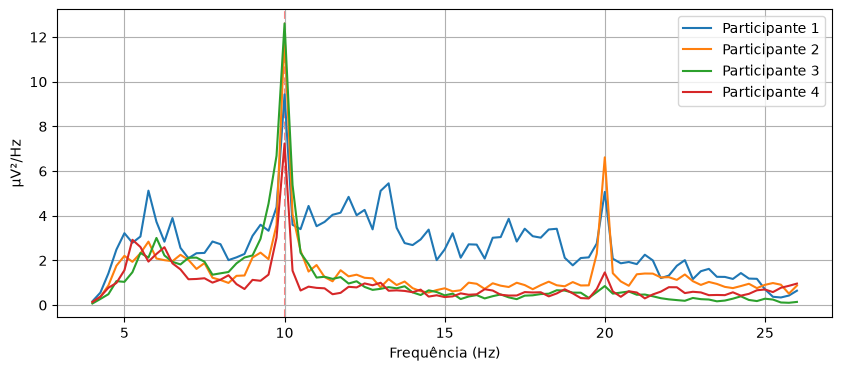

In [7]:
plt.figure(figsize=(10, 4))
for p, e in epocas_filtradas.items():
    psd, f = espectro(e["10 Hz"], 4, 26)
    plt.plot(f, psd.mean(axis=0), label=f"Participante {p}")

plt.axvline(10, color="red", linestyle="--", alpha=0.5, zorder=0)
plt.xlabel("Frequência (Hz)")
plt.ylabel("µV²/Hz")
plt.legend()
plt.grid(True)
plt.show()